# Exploration : roulement sain vs défaut bague intérieure (IR 0.007", 0 HP)
Données CWRU, accéléromètre côté entraînement (DE), échantillonné à 12 kHz.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.stats import kurtosis
sain   = loadmat("../data/normal/97.mat")
defaut = loadmat("../data/12k-DE/105.mat")

print(sain.keys())
print(defaut.keys())

dict_keys(['__header__', '__version__', '__globals__', 'X097_DE_time', 'X097_FE_time', 'X097RPM'])
dict_keys(['__header__', '__version__', '__globals__', 'X105_DE_time', 'X105_FE_time', 'X105_BA_time', 'X105RPM'])


In [2]:
# extraire les signaux
x_sain = np.ravel(sain["X097_DE_time"])
x_def  = np.ravel(defaut["X105_DE_time"])

print("Sain :", len(x_sain), "points")
print("Défaut IR :", len(x_def), "points")

Sain : 243938 points
Défaut IR : 121265 points


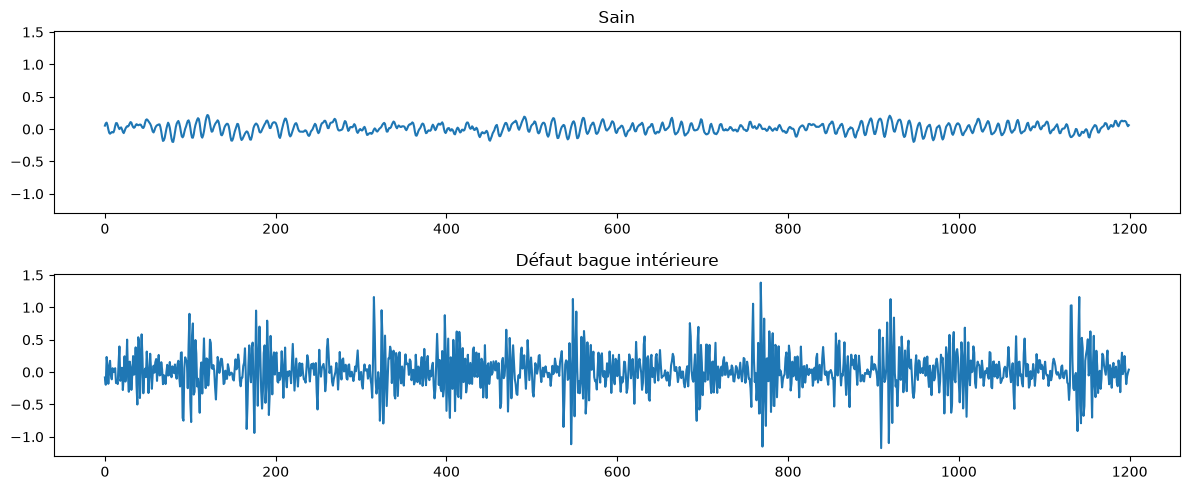

In [3]:
# comparer 0,1 s des deux signaux
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharey=True)
axes[0].plot(x_sain[:1200]);  axes[0].set_title("Sain")
axes[1].plot(x_def[:1200]);   axes[1].set_title("Défaut bague intérieure")
plt.tight_layout()
plt.show()

In [4]:
def indicateurs(x):
    rms = np.sqrt(np.mean(x**2))
    pic = np.max(np.abs(x))
    return {"RMS": rms, "Pic": pic, "Crête": pic / rms,
            "Kurtosis": kurtosis(x, fisher=False)}

tableau = pd.DataFrame({"Sain": indicateurs(x_sain),
                        "Défaut IR": indicateurs(x_def)}).T.round(2)
tableau

,RMS,Pic,Crête,Kurtosis
Sain,0.07,0.31,4.22,2.76
Défaut IR,0.29,1.74,5.97,5.40
